# Task 1 · Notebook 02 — Cleaning & Exploratory Analysis

**Input:** `data/raw/skytrax_ba_reviews_2026-02.csv` (4,018 raw reviews, see Notebook 01)
**Output:** `data/processed/reviews_clean.csv`

Cleaning follows the decisions made in Notebook 01:
1. Placeholder text (`"No Aircraft"`, `"No rating"`) becomes proper missing values. Nothing is invented.
2. Reviews with the generic title "British Airways customer review" are kept for rating analysis but flagged, so they can be excluded from text analysis.
3. Only true duplicates are removed.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

RAW_FILE = Path("data/raw/skytrax_ba_reviews_2026-02.csv")
OUT_FILE = Path("data/processed/reviews_clean.csv")

df = pd.read_csv(RAW_FILE)

# "Type of Traveller" -> "type_of_traveller": lowercase, no spaces, easier to type
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
print(df.columns.tolist())

['review_title', 'aircraft', 'type_of_traveller', 'seat_type', 'route', 'date_flown', 'seat_comfort', 'cabin_staff_service', 'food_beverages', 'inflight_entertainment', 'ground_service', 'value_for_money']


In [2]:
# Every column except the title: replace "No Aircraft", "No rating", etc. with NaN.
# The title is excluded on purpose: a real title like "No legroom at all" must not be wiped.
detail_cols = df.columns.drop("review_title")
df[detail_cols] = df[detail_cols].replace(r"^No .*", np.nan, regex=True)

# Remove the quote marks around titles: '"the crew were awful"' -> 'the crew were awful'
df["review_title"] = df["review_title"].str.strip('"').str.strip()

df.isna().sum()

review_title                 0
aircraft                  1917
type_of_traveller          771
seat_type                    2
route                      776
date_flown                 778
seat_comfort               134
cabin_staff_service        151
food_beverages             468
inflight_entertainment    1298
ground_service             856
value_for_money              0
dtype: int64

In [3]:
RATING_COLS = ["seat_comfort", "cabin_staff_service", "food_beverages",
               "inflight_entertainment", "ground_service", "value_for_money"]

# Ratings: text -> whole numbers. "Int64" (capital I) is pandas' integer type that allows missing values.
for col in RATING_COLS:
    df[col] = pd.to_numeric(df[col]).astype("Int64")

# Skytrax stars run from 1 to 5, so a 0 means "the scraper found no filled stars", not a real score.
zero_counts = (df[RATING_COLS] == 0).sum()
print("Zero ratings found (invalid, set to missing):")
print(zero_counts[zero_counts > 0])
df[RATING_COLS] = df[RATING_COLS].replace(0, pd.NA)

# "February 2026" -> a real date (the 1st of that month)
df["date_flown"] = pd.to_datetime(df["date_flown"], format="%B %Y", errors="coerce")

print("\nDate range:", df["date_flown"].min().date(), "to", df["date_flown"].max().date())
df[RATING_COLS].describe().T[["count", "min", "max", "mean"]].round(2)

Zero ratings found (invalid, set to missing):
food_beverages             1
inflight_entertainment    10
value_for_money            1
dtype: Int64

Date range: 2014-07-01 to 2026-02-01


,count,min,max,mean
seat_comfort,3884.0,1.0,5.0,2.86
cabin_staff_service,3867.0,1.0,5.0,3.23
food_beverages,3549.0,1.0,5.0,2.71
inflight_entertainment,2710.0,1.0,5.0,2.65
ground_service,3162.0,1.0,5.0,2.75
value_for_money,4017.0,1.0,5.0,2.65


In [4]:
# Flag reviews whose title is the generic site label rather than the passenger's own words
df["has_informative_title"] = ~df["review_title"].str.contains(
    "british airways customer review", case=False
)

# A TRUE duplicate = identical in every column AND has an informative title.
# (Generic-title rows can look identical simply because older reviews lack route/date/traveller.)
true_dupes = df.duplicated(keep="first") & df["has_informative_title"]

print("True duplicates:")
display(df[df.duplicated(keep=False) & df["has_informative_title"]][
    ["review_title", "route", "date_flown", "seat_type"]
])

df = df[~true_dupes].reset_index(drop=True)
print(f"Removed {true_dupes.sum()} true duplicates -> {len(df):,} reviews remain")
print(f"Reviews with an informative title: {df['has_informative_title'].sum():,}")

True duplicates:


,review_title,route,date_flown,seat_type
2670,degraded its economy product,PHL to LHR,2016-03-01,Economy Class
2672,degraded its economy product,PHL to LHR,2016-03-01,Economy Class
2846,"comfortable, if narrow, seats",Tampa to Gatwick,2015-11-01,Business Class
2847,crummy Boeing 747s,LHR to MIA,2015-11-01,Premium Economy
2874,"comfortable, if narrow, seats",Tampa to Gatwick,2015-11-01,Business Class
2876,crummy Boeing 747s,LHR to MIA,2015-11-01,Premium Economy


Removed 3 true duplicates -> 4,015 reviews remain
Reviews with an informative title: 3,057


In [5]:
# How many of the 6 star ratings did each passenger actually give?
df["n_ratings"] = df[RATING_COLS].notna().sum(axis=1)

# Average of the ratings the passenger DID give (missing ones are skipped, not treated as 0)
df["avg_rating"] = df[RATING_COLS].astype(float).mean(axis=1).round(2)

# Year of travel, handy for trends over time
df["year_flown"] = df["date_flown"].dt.year.astype("Int64")

print("How many ratings each review has:")
print(df["n_ratings"].value_counts().sort_index())
print("\nReviews per year flown:")
print(df["year_flown"].value_counts().sort_index())

How many ratings each review has:
n_ratings
1      75
2      59
3      17
4     313
5    1631
6    1920
Name: count, dtype: int64

Reviews per year flown:
year_flown
2014      9
2015    472
2016    562
2017    560
2018    338
2019    336
2020     94
2021     93
2022    217
2023    278
2024    170
2025     92
2026     16
Name: count, dtype: Int64


In [6]:
OUT_FILE.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(OUT_FILE, index=False)

print(f"Saved {len(df):,} rows x {df.shape[1]} columns to {OUT_FILE}")
df.info()

Saved 4,015 rows x 16 columns to data\processed\reviews_clean.csv
<class 'pandas.DataFrame'>
RangeIndex: 4015 entries, 0 to 4014
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   review_title            4015 non-null   str           
 1   aircraft                2098 non-null   str           
 2   type_of_traveller       3244 non-null   str           
 3   seat_type               4013 non-null   str           
 4   route                   3239 non-null   str           
 5   date_flown              3237 non-null   datetime64[us]
 6   seat_comfort            3881 non-null   Int64         
 7   cabin_staff_service     3864 non-null   Int64         
 8   food_beverages          3546 non-null   Int64         
 9   inflight_entertainment  2707 non-null   Int64         
 10  ground_service          3159 non-null   Int64         
 11  value_for_money         4014 non-null   Int64        

## Exploratory analysis

### 1. How have reviews changed over time?

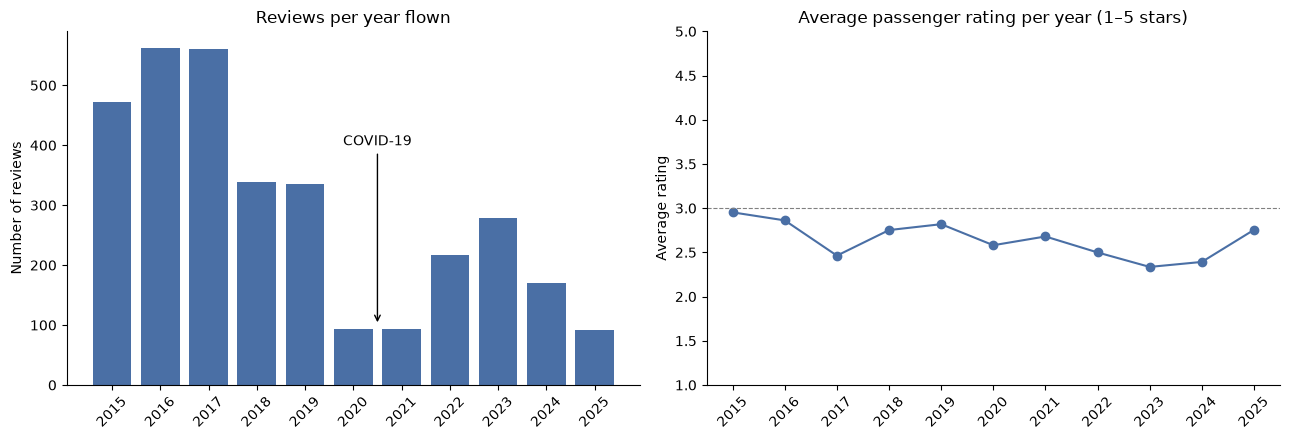

,reviews,avg_rating
year_flown,,
2015,472,2.95
2016,562,2.86
2017,560,2.46
2018,338,2.75
2019,336,2.82
2020,94,2.58
2021,93,2.68
2022,217,2.50
2023,278,2.34


In [7]:
import matplotlib.pyplot as plt

# 2014 (9 reviews) and 2026 (16, year in progress) are too small to compare fairly
yearly = (
    df[df["year_flown"].between(2015, 2025)]
    .groupby("year_flown")
    .agg(reviews=("avg_rating", "size"), avg_rating=("avg_rating", "mean"))
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

ax1.bar(yearly.index, yearly["reviews"], color="#4a6fa5")
ax1.set_title("Reviews per year flown")
ax1.set_ylabel("Number of reviews")
ax1.annotate("COVID-19", xy=(2020.5, 100), xytext=(2020.5, 400),
             ha="center", arrowprops=dict(arrowstyle="->"))

ax2.plot(yearly.index, yearly["avg_rating"], marker="o", color="#4a6fa5")
ax2.set_title("Average passenger rating per year (1–5 stars)")
ax2.set_ylabel("Average rating")
ax2.set_ylim(1, 5)
ax2.axhline(3, color="grey", linestyle="--", linewidth=0.8)  # mid-point of the scale

for ax in (ax1, ax2):
    ax.set_xticks(yearly.index)
    ax.tick_params(axis="x", rotation=45)
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

yearly.round(2)

**Observations**
- **Volume:** reviews fell from ~560 a year (2016–2017) to ~95 a year in 2020–2021, reflecting the collapse in air travel during COVID-19, then partly recovered.
- **Satisfaction:** the average rating has stayed **below the scale midpoint (3)** in every year from 2015 to 2025, drifting down from 2.95 (2015) to a low of 2.34 (2023) before improving to 2.75 in 2025.
- **2017 dip (2.46):** stands out against neighbouring years and may line up with known events that year (e.g. BA's switch to paid food on short-haul economy and its May 2017 IT outage). This is a hypothesis, not proven by this data.

**Caveats**
- Skytrax reviews are **self-selected**: unhappy passengers are more motivated to write, so absolute levels likely understate typical satisfaction. Trends over time are more trustworthy than the level itself.
- 2025 is based on only 92 reviews, so its recovery should be treated with caution.

### 2. Which parts of the service do passengers rate worst?

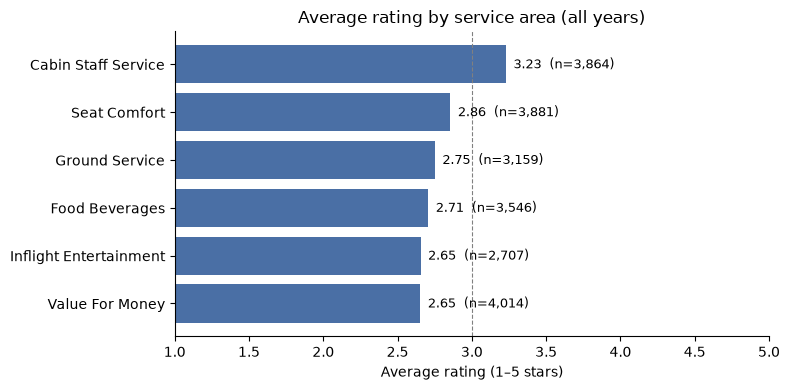

In [8]:
# Average of each rating column, worst first
service = (
    df[RATING_COLS]
    .astype(float)
    .agg(["mean", "count"])
    .T
    .sort_values("mean")
)
service.index = service.index.str.replace("_", " ").str.title()   # "seat_comfort" -> "Seat Comfort"

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(service.index, service["mean"], color="#4a6fa5")
ax.axvline(3, color="grey", linestyle="--", linewidth=0.8)
ax.set_xlim(1, 5)
ax.set_xlabel("Average rating (1–5 stars)")
ax.set_title("Average rating by service area (all years)")
for i, (m, n) in enumerate(zip(service["mean"], service["count"])):
    ax.text(m + 0.05, i, f"{m:.2f}  (n={int(n):,})", va="center", fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Observations**
- **Cabin Staff Service (3.23)** is the only area rated above the scale midpoint, so crew are BA's relative strength.
- **Value For Money (2.65)** and **Inflight Entertainment (2.65)** are rated worst.
- Every other area sits between 2.7 and 2.9, below average but close together.

A low score alone does not tell BA where to act first. The next question is which of these areas actually *matters most* to passengers.

### 3. What should BA fix first? (Importance vs performance)

- **Performance** = the average rating of each service area (from the chart above).
- **Importance** = how strongly each area moves with *Value For Money*, measured with Spearman correlation. If passengers who rate an area low also tend to feel the trip was poor value, that area matters to them.

Areas that are **important but poorly rated** are the priorities.

**Observations**
- **Fix first:** *Food & Beverages* (2.71) and *Ground Service* (2.75) are rated below average **and** are among the areas most closely linked to perceived value.
- **Borderline:** *Seat Comfort* is just as important (0.69) and only slightly above the average performance line, so it is close to the "fix first" zone.
- **Protect:** *Cabin Staff Service* is BA's strongest area (3.23) and still important.
- **Lower priority:** *Inflight Entertainment* is rated poorly, but it is the area least connected to value (0.51), so improving it would likely shift perceptions less.

**Caveat:** importance scores for the top four areas are close (0.66–0.70), so the ranking among them is not sharp. Correlation also shows association, not cause: it suggests where to look, not proof that fixing food would raise value ratings.

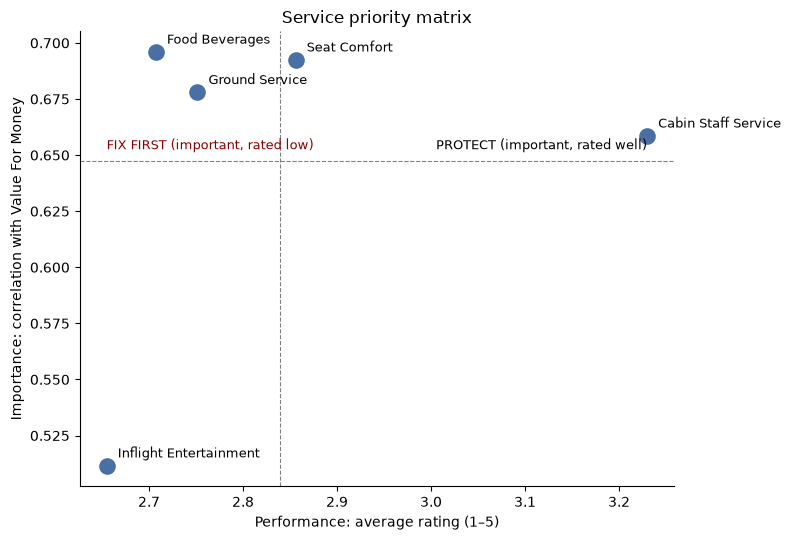

,performance,importance
Food Beverages,2.71,0.70
Seat Comfort,2.86,0.69
Ground Service,2.75,0.68
Cabin Staff Service,3.23,0.66
Inflight Entertainment,2.65,0.51


In [9]:
drivers = [c for c in RATING_COLS if c != "value_for_money"]
ratings = df[RATING_COLS].astype(float)

matrix = pd.DataFrame({
    "performance": ratings[drivers].mean(),
    "importance": ratings[drivers].corrwith(ratings["value_for_money"], method="spearman"),
})
matrix.index = matrix.index.str.replace("_", " ").str.title()

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(matrix["performance"], matrix["importance"], s=120, color="#4a6fa5")
for name, row in matrix.iterrows():
    ax.annotate(name, (row["performance"], row["importance"]),
                xytext=(8, 6), textcoords="offset points", fontsize=9)

# Quadrant lines at the average of each axis
ax.axvline(matrix["performance"].mean(), color="grey", linestyle="--", linewidth=0.8)
ax.axhline(matrix["importance"].mean(), color="grey", linestyle="--", linewidth=0.8)

# Quadrant labels, placed just above the horizontal line so they don't cover any points
y_label = matrix["importance"].mean() + 0.004
ax.text(matrix["performance"].min(), y_label, "FIX FIRST (important, rated low)",
        fontsize=9, color="#8b0000", va="bottom")
ax.text(matrix["performance"].max(), y_label, "PROTECT (important, rated well)",
        fontsize=9, ha="right", va="bottom")

ax.set_xlabel("Performance: average rating (1–5)")
ax.set_ylabel("Importance: correlation with Value For Money")
ax.set_title("Service priority matrix")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

matrix.sort_values("importance", ascending=False).round(2)

### 4. How does the experience differ by cabin class?

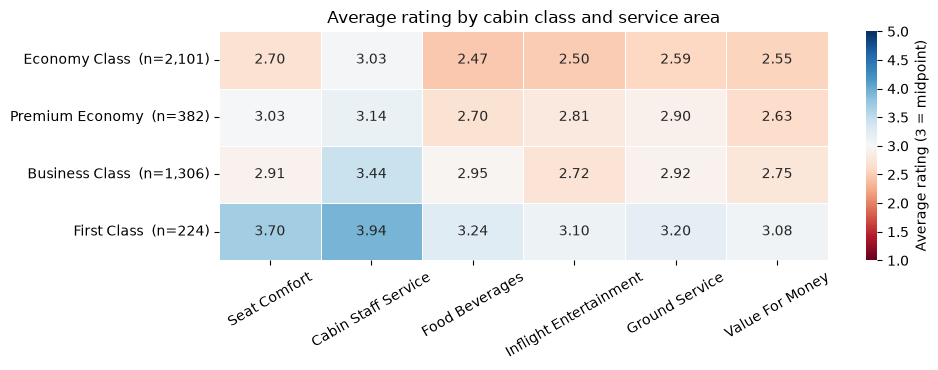

In [10]:
import seaborn as sns

cabin_order = ["Economy Class", "Premium Economy", "Business Class", "First Class"]

by_cabin = (
    df[RATING_COLS].astype(float)          # plain floats, which seaborn can draw
      .groupby(df["seat_type"])
      .mean()
      .reindex(cabin_order)
)
by_cabin.columns = by_cabin.columns.str.replace("_", " ").str.title()
counts = df["seat_type"].value_counts().reindex(cabin_order)
by_cabin.index = [f"{c}  (n={counts[c]:,})" for c in cabin_order]

fig, ax = plt.subplots(figsize=(10, 3.8))
sns.heatmap(by_cabin, annot=True, fmt=".2f", cmap="RdBu", center=3, vmin=1, vmax=5,
            linewidths=0.5, cbar_kws={"label": "Average rating (3 = midpoint)"}, ax=ax)
ax.set_title("Average rating by cabin class and service area")
ax.set_ylabel("")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

**Observations**
- **First Class** scores highest in every area, and **Economy** lowest in every area, as expected.
- **Surprise:** *Business Class Seat Comfort (2.91) is rated lower than Premium Economy (3.03)*, and Business also trails Premium Economy on Inflight Entertainment.
- **Value For Money barely rises with the fare.** It goes from 2.55 in Economy to only 2.75 in Business. Only First Class (3.08) gets above the midpoint, so passengers in premium cabins mostly do not feel they get proportionally more value.
- Cabin Staff Service is the top-rated area within every cabin.

**Hypothesis:** BA's older Club World business seat was widely criticised and has been gradually replaced by the "Club Suite" since 2019. If that matters, Business seat ratings should be higher from 2019 onwards. Tested below.

In [11]:
business = df[(df["seat_type"] == "Business Class") & df["year_flown"].notna()].copy()
business["period"] = np.where(business["year_flown"] >= 2019, "2019–2026", "2014–2018")

business.groupby("period")["seat_comfort"].agg(["mean", "count"]).astype(float).round(2)

,mean,count
period,,
2014–2018,2.75,563.0
2019–2026,2.91,421.0


In [12]:
from scipy.stats import mannwhitneyu

before = business.loc[business["period"] == "2014–2018", "seat_comfort"].dropna().astype(float)
after  = business.loc[business["period"] == "2019–2026", "seat_comfort"].dropna().astype(float)

stat, p_value = mannwhitneyu(after, before, alternative="greater")
print(f"Before 2019: mean {before.mean():.2f} (n={len(before)})")
print(f"From 2019:   mean {after.mean():.2f} (n={len(after)})")
print(f"Mann-Whitney U test, one-sided p-value: {p_value:.3f}")

Before 2019: mean 2.75 (n=563)
From 2019:   mean 2.91 (n=421)
Mann-Whitney U test, one-sided p-value: 0.042


**Result:** Business Class seat comfort rose from 2.75 (2014–2018, n=563) to 2.91 (2019–2026, n=421). A one-sided Mann-Whitney U test gives p ≈ 0.04.

**Verdict: weak support.** The improvement is statistically significant at the 5% level, but small (+0.16 stars), and Business seats are *still* rated below Premium Economy. The data cannot show *which* seat each passenger had, and the Club Suite was rolled out gradually, so this is consistent with the hypothesis rather than proof of it.

### 5. Which types of traveller are most and least satisfied?

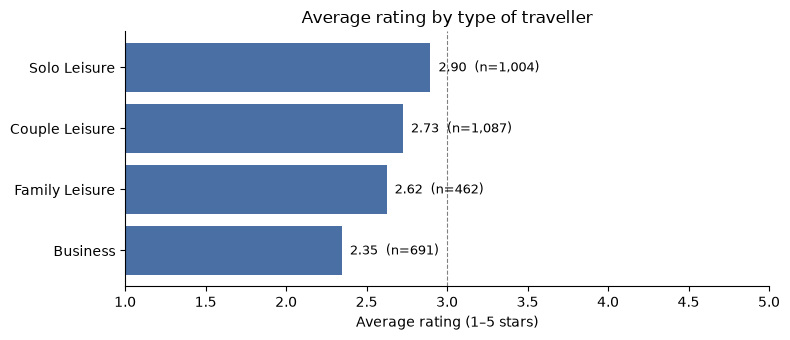

In [13]:
by_traveller = (
    df.dropna(subset=["type_of_traveller"])
      .groupby("type_of_traveller")
      .agg(avg_rating=("avg_rating", "mean"), reviews=("avg_rating", "size"))
      .sort_values("avg_rating")
)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(by_traveller.index, by_traveller["avg_rating"], color="#4a6fa5")
ax.axvline(3, color="grey", linestyle="--", linewidth=0.8)
ax.set_xlim(1, 5)
ax.set_xlabel("Average rating (1–5 stars)")
ax.set_title("Average rating by type of traveller")
for i, (m, n) in enumerate(zip(by_traveller["avg_rating"], by_traveller["reviews"])):
    ax.text(m + 0.05, i, f"{m:.2f}  (n={n:,})", va="center", fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

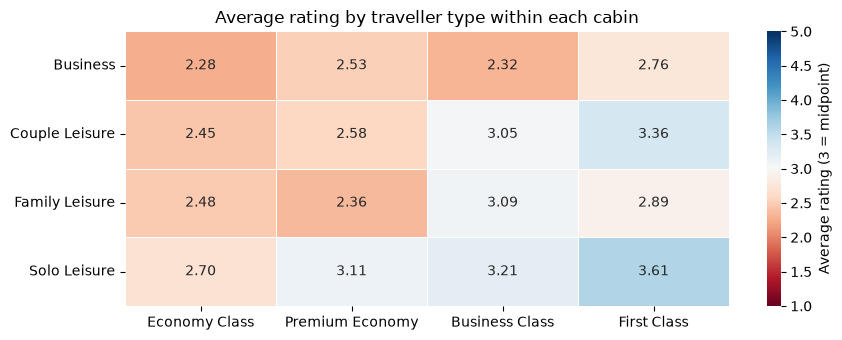

In [14]:
cabin_traveller = (
    df.dropna(subset=["type_of_traveller", "seat_type"])
      .pivot_table(index="type_of_traveller", columns="seat_type",
                   values="avg_rating", aggfunc="mean")
      [cabin_order]
)

fig, ax = plt.subplots(figsize=(9, 3.5))
sns.heatmap(cabin_traveller, annot=True, fmt=".2f", cmap="RdBu", center=3, vmin=1, vmax=5,
            linewidths=0.5, cbar_kws={"label": "Average rating (3 = midpoint)"}, ax=ax)
ax.set_title("Average rating by traveller type within each cabin")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

**Observations**
- **Business travellers are the least satisfied group (2.35)** and **Solo Leisure travellers the most satisfied (2.90)**. This is the *opposite* of what the original version of this project claimed.
- **Checking for a confounder:** business travellers fly Business Class more often, so the cabin could have explained the gap. But within the **same cabin**, business travellers still rate lowest in three of four cabins. In Business Class itself they give 2.32, versus 3.05–3.21 from leisure travellers.
- The gap is therefore linked to the *type of traveller*, not just the cabin.

**Possible explanations (hypotheses, not tested here):** frequent business flyers compare BA with many other airlines, have higher expectations, and are more affected by delays and disruption because their trip has a purpose and a schedule.

**Business relevance:** business travellers are typically among an airline's highest-value customers, which makes this the most commercially important finding in the review data.

## Key findings (Notebook 02)

1. **Satisfaction is below the midpoint every year from 2015 to 2025**, declining from 2.95 (2015) to 2.34 (2023) with partial recovery in 2025; review volume collapsed during COVID-19.
2. **Cabin crew are BA's strength** (3.23, the only area above 3); **Value For Money and Inflight Entertainment are weakest** (2.65).
3. **Priority to fix: Food & Beverages and Ground Service**: rated low and closely linked to perceived value.
4. **Business Class seats are rated below Premium Economy seats**; a small but statistically significant improvement since 2019 (p ≈ 0.04) weakly supports the Club Suite rollout having helped.
5. **Business travellers are the least satisfied group** overall, and the least satisfied in three of the four cabins.

**Caveat throughout:** Skytrax reviews are self-selected and likely skew negative; relative comparisons are more reliable than absolute levels.

**Next:** Notebook 03 builds a sentiment model from the review titles.